# Simulations microéconomiques de l’inflation et des budgets au Maroc

Projet individuel de première année à l’INSEA. L’analyse associe les coefficients budgétaires annuels de l’ENNVM 2022–2023 aux séries mensuelles d’IPC du HCP. Elle compare 18 profils agrégés, définis par le milieu et les quintiles de **dépense annuelle par personne**.

- **Prudent** — groupes 01, 03, 05 et 10. Correspondances fiables à l’échelle des divisions.
- **Élargi** — groupes 01 à 11 et 13. Les correspondances partielles servent au test de sensibilité.
- Les groupes 12 et 14 restent hors des deux sous-paniers. Les séries de prix sont communes à tous les profils. Leur collecte est urbaine, ce qui limite l’interprétation pour les profils ruraux. [Méthodologie de l’IPC du HCP](https://m.hcp.ma/Note-methodologique-sur-l-Indice-des-Prix-a-la-Consommation-Base-100-2017_a4095.html)

Les trajectoires historiques reposent sur les **prix observés** par le HCP et les poids fixes de l’enquête. Les deux chocs de prix sont **hypothétiques**. Les taux calculés décrivent les postes couverts, et les contributions au budget initial indiquent uniquement l’effet de ces postes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

racine = Path.cwd()
if racine.name == "notebooks":
    racine = racine.parent
traite = racine / "data" / "processed"
sorties = racine / "outputs"
sorties.mkdir(exist_ok=True)

ipc = pd.read_csv(traite / "ipc_maroc_mensuel.csv", index_col="date", parse_dates=["date"])
budgets = pd.read_csv(traite / "depenses_menages_2022_2023.csv")
profils = pd.read_csv(traite / "profils_budgetaires_2022_2023.csv").set_index("profil")
liens = pd.read_csv(traite / "correspondance_depenses_ipc.csv").set_index("code_groupe")

perimetres = {"prudent": [1, 3, 5, 10], "elargi": list(range(1, 12)) + [13]}
milieux = ["National", "Urbain", "Rural"]
classes = ["C1", "C2", "C3", "C4", "C5", "Total"]
profils_attendus = [f"{milieu}_{classe}" for milieu in milieux for classe in classes]
reference = pd.Timestamp("2022-09-01")
budget_initial_mad = 5000

# Vérifier les dimensions, les clés et les valeurs avant de calculer les taux.
calendrier = pd.date_range("2017-01-01", "2026-10-01", freq="MS")
if ipc.shape != (118, 15) or not ipc.index.equals(calendrier) or not ipc.columns.is_unique:
    raise ValueError("Le CSV IPC doit contenir 15 séries et les 118 mois attendus dans l’ordre.")
if not np.isfinite(ipc.to_numpy(dtype=float)).all() or ipc.le(0).any().any():
    raise ValueError("Les indices IPC doivent être finis et strictement positifs.")
if not profils.index.is_unique or set(profils.index) != set(profils_attendus):
    raise ValueError("La table des profils doit contenir les 18 profils attendus.")
profils = profils.reindex(profils_attendus)
if not liens.index.is_unique or set(liens.index) != set(range(1, 15)):
    raise ValueError("La correspondance doit contenir les 14 groupes ENNVM.")
if budgets.duplicated(["profil", "code_groupe"]).any() or len(budgets) != 18 * 14:
    raise ValueError("Chaque couple profil et groupe doit être présent une fois.")

cb = budgets.pivot(index="profil", columns="code_groupe", values="coefficient_budgetaire_pct")
if set(cb.index) != set(profils_attendus) or set(cb.columns) != set(range(1, 15)):
    raise ValueError("Les profils et groupes du fichier de dépenses sont inattendus.")
cb = cb.reindex(profils_attendus)
if not np.isfinite(cb.to_numpy(dtype=float)).all() or cb.lt(0).any().any():
    raise ValueError("Les coefficients doivent être renseignés, finis et non négatifs.")
if cb.sum(axis=1).sub(100).abs().gt(14 * 0.05 + 1e-9).any():
    raise ValueError("Un total budgétaire est hors tolérance d’arrondi.")
np.testing.assert_allclose(cb.sum(axis=1), profils["somme_cb_postes_pct"], atol=1e-9, rtol=0)

proches = set(liens.index[liens["statut"] == "proche"])
partiels = set(liens.index[liens["statut"] == "partiel"])
absents = set(liens.index[liens["statut"] == "absent"])
if proches != set(perimetres["prudent"]) or proches | partiels != set(perimetres["elargi"]) or absents != {12, 14}:
    raise ValueError("Le fichier de correspondance ne confirme pas les périmètres validés.")
colonnes = liens.loc[perimetres["elargi"], "colonne_ipc_candidate"]
if colonnes.isna().any() or not colonnes.is_unique or not colonnes.isin(ipc.columns).all():
    raise ValueError("Divisions IPC manquantes ou en double dans la correspondance.")
if reference not in ipc.index:
    raise ValueError("Septembre 2022 doit figurer dans les séries mensuelles.")
print("Contrôles des fichiers réussis : 18 profils, 14 groupes ENNVM et 118 mois d’IPC.")

Contrôles des fichiers réussis : 18 profils, 14 groupes ENNVM et 118 mois d’IPC.


## 1. Trajectoires historiques du coût des sous-paniers

Septembre 2022 sert de repère commun, près du milieu de la collecte (15 mars 2022 au 14 mars 2023). Il fixe chaque indice de coût à 100. Les coefficients décrivent la période d’enquête entière et leur application aux autres années est une simulation à composition fixe. [Rapport ENNVM du HCP](https://www.hcp.ma/Rapport-des-resultats-de-l-Enquete-Nationale-sur-le-Niveau-de-Vie-des-Menages-2022-2023_a4062.html)

Pour le profil $p$, le périmètre $S$ et le mois de référence $b$, la couverture publiée vaut $C_p=\sum_{k\in S}CB_{p,k}$, en pourcentage du budget total. On renormalise les coefficients pour calculer l’indice du sous-panier :

$$
P_{p,t}=100\sum_{k\in S}\frac{CB_{p,k}}{C_p}\frac{IPC_{k,t}}{IPC_{k,b}}.
$$

La variation depuis septembre 2022 vaut $P_{p,t}-100$ en pourcentage. Sa contribution en points du budget total **initial** vaut $(C_p/100)(P_{p,t}-100)$. Les variations mensuelles et sur douze mois comparent deux niveaux du sous-panier. Les tableaux ne leur appliquent pas la couverture initiale, car la part du sous-panier au début de ces intervalles peut différer. Les premiers mois sans comparaison restent vides.

Le calcul ci-dessous reprend la formule de `simuler_panier` de la phase 3. Il vérifie aussi l’indice par une somme directe des variations de prix pondérées par les coefficients publiés.

In [2]:
def estimer_cout(perimetre):
    """Calculer l’indice des 18 sous-paniers et leurs contributions au budget initial."""
    codes = perimetres[perimetre]
    indices = ipc[liens.loc[codes, "colonne_ipc_candidate"].tolist()].copy()
    indices.columns = codes
    coefficients = cb[codes]
    couverture = coefficients.sum(axis=1)
    if couverture.le(0).any():
        raise ValueError("La couverture doit être strictement positive pour chaque profil.")

    poids = coefficients.div(couverture, axis=0)
    rapports = indices.div(indices.loc[reference])
    cout = 100 * rapports.dot(poids.T)
    mensuel = 100 * (cout / cout.shift(1) - 1)
    annuel = 100 * (cout / cout.shift(12) - 1)

    np.testing.assert_allclose(poids.sum(axis=1), 1, atol=1e-12)
    np.testing.assert_allclose(cout.loc[reference], 100, atol=1e-10, rtol=0)
    assert np.isfinite(cout.to_numpy()).all() and cout.gt(0).all().all()
    assert mensuel.isna().to_numpy().sum() == 18
    assert annuel.isna().to_numpy().sum() == 12 * 18

    # Calcul direct de la contribution avec les coefficients d’origine.
    variation = cout - 100
    contribution = rapports.sub(1).dot(coefficients.T)
    np.testing.assert_allclose(contribution, variation.mul(couverture / 100), atol=1e-10, rtol=0)
    return couverture, cout, mensuel, annuel, contribution


historiques, poids_export = [], []
for perimetre, codes in perimetres.items():
    couverture, cout, mensuel, annuel, contribution = estimer_cout(perimetre)
    for profil in profils.index:
        historiques.append(pd.DataFrame({
            "date": ipc.index,
            "perimetre": perimetre,
            "profil": profil,
            "couverture_budget_pct": couverture.loc[profil],
            "indice_cout_sous_panier_base_100_sept_2022": cout[profil].to_numpy(),
            "variation_depuis_sept_2022_pct": cout[profil].to_numpy() - 100,
            "variation_mensuelle_sous_panier_pct": mensuel[profil].to_numpy(),
            "glissement_annuel_sous_panier_pct": annuel[profil].to_numpy(),
            "contribution_depuis_sept_2022_budget_initial_points": contribution[profil].to_numpy(),
        }))
        for code in codes:
            coefficient = cb.loc[profil, code]
            poids_export.append({
                "perimetre": perimetre, "profil": profil, "code_groupe": code,
                "groupe_enquete": liens.loc[code, "groupe_enquete"],
                "division_ipc": liens.loc[code, "colonne_ipc_candidate"],
                "statut_correspondance": liens.loc[code, "statut"],
                "coefficient_budget_initial_pct": coefficient,
                "couverture_budget_pct": couverture.loc[profil],
                "poids_sous_panier_pct": 100 * coefficient / couverture.loc[profil],
            })

historique = pd.concat(historiques, ignore_index=True)
poids_table = pd.DataFrame(poids_export)
assert len(historique) == 118 * 18 * 2 and not historique.duplicated(["date", "perimetre", "profil"]).any()
np.testing.assert_allclose(
    poids_table.groupby(["perimetre", "profil"])["poids_sous_panier_pct"].sum(), 100
)
derniere_date = historique.loc[historique["date"].eq(ipc.index[-1])].copy()
derniere_date["date"] = derniere_date["date"].dt.strftime("%Y-%m-%d")
display(derniere_date.round(2))

,date,perimetre,profil,couverture_budget_pct,indice_cout_sous_panier_base_100_sept_2022,variation_depuis_sept_2022_pct,variation_mensuelle_sous_panier_pct,glissement_annuel_sous_panier_pct,contribution_depuis_sept_2022_budget_initial_points
117,2026-10-01,prudent,National_C1,51.9,109.42,9.42,1.39,0.24,4.89
235,2026-10-01,prudent,National_C2,48.8,109.38,9.38,1.37,0.25,4.58
353,2026-10-01,prudent,National_C3,46.2,109.36,9.36,1.34,0.26,4.32
471,2026-10-01,prudent,National_C4,43.0,109.31,9.31,1.31,0.28,4.00
589,2026-10-01,prudent,National_C5,36.1,109.04,9.04,1.16,0.38,3.26
707,2026-10-01,prudent,National_Total,41.4,109.22,9.22,1.26,0.31,3.82
825,2026-10-01,prudent,Urbain_C1,45.0,109.39,9.39,1.36,0.25,4.23
943,2026-10-01,prudent,Urbain_C2,43.5,109.35,9.35,1.33,0.27,4.07
1061,2026-10-01,prudent,Urbain_C3,42.3,109.31,9.31,1.30,0.28,3.94
1179,2026-10-01,prudent,Urbain_C4,40.4,109.26,9.26,1.26,0.31,3.74


## 2. Chocs hypothétiques et budget illustratif de 5 000 MAD

1. **Hausse uniforme** — tous les postes du sous-panier augmentent de 5 %.
2. **Hausse uniforme et choc alimentaire supplémentaire** — le groupe 01 augmente de 10 % **sur son prix déjà majoré de 5 %**. Sa hausse totale est donc $100(1{,}05\times1{,}10-1)=15{,}5\,\%$. Les autres postes couverts restent à +5 %. L’écart avec le choc uniforme vaut 10,5 points de prix sur le groupe 01.

Pour un poste dont le coefficient d’origine est $CB_k$ et le choc $\delta_k$ en fraction, sa contribution au budget total initial vaut $CB_k\delta_k$ en points. Le supplément illustratif en MAD vaut $5000$ fois la contribution totale divisée par 100. Chaque montant concerne les postes couverts. Une hausse de 5 % sur **l’ensemble** d’un budget de 5 000 MAD représenterait 250 MAD. Les montants du tableau mesurent uniquement la fraction attribuable au sous-panier.

Le budget de 5 000 MAD sert d’illustration commune à tous les profils. Les postes non couverts restent sans estimation et les quantités sont tenues fixes. Les écarts de dépenses observées ou de revenu ne sont pas estimés.

In [3]:
chocs = {
    "uniforme_5pct": 0.05,
    "uniforme_5pct_puis_alimentaire_10pct": 1.05 * 1.10 - 1,
}
resultats_chocs = []
for perimetre, codes in perimetres.items():
    coefficients = cb[codes]
    couverture = coefficients.sum(axis=1)
    for choc, taux_alimentaire in chocs.items():
        # Les taux sont en fractions dans le calcul, par exemple 0,05 pour 5 %.
        taux = pd.Series(0.05, index=codes)
        taux.loc[1] = taux_alimentaire
        contribution = coefficients.dot(taux)
        variation = 100 * contribution / couverture
        supplement = budget_initial_mad * contribution / 100
        resultats_chocs.append(pd.DataFrame({
            "profil": profils.index,
            "perimetre": perimetre,
            "choc_hypothetique": choc,
            "couverture_budget_pct": couverture.to_numpy(),
            "hausse_prix_groupe_01_pct": 100 * taux_alimentaire,
            "hausse_prix_autres_postes_couverts_pct": 5.0,
            "variation_cout_sous_panier_pct": variation.to_numpy(),
            "contribution_budget_initial_points": contribution.to_numpy(),
            "budget_initial_hypothetique_mad": budget_initial_mad,
            "cout_initial_postes_couverts_mad": (budget_initial_mad * couverture / 100).to_numpy(),
            "supplement_postes_couverts_mad": supplement.to_numpy(),
        }))

hypotheses = pd.concat(resultats_chocs, ignore_index=True)
cles = ["perimetre", "profil"]
uniforme = hypotheses[hypotheses["choc_hypothetique"].eq("uniforme_5pct")].set_index(cles)
combine = hypotheses[~hypotheses["choc_hypothetique"].eq("uniforme_5pct")].set_index(cles)
assert len(hypotheses) == 72 and uniforme.index.is_unique and uniforme.index.equals(combine.index)

# Tests sur les propriétés attendues et sur l’effet marginal du choc alimentaire.
np.testing.assert_allclose(uniforme["variation_cout_sous_panier_pct"], 5)
np.testing.assert_allclose(combine["hausse_prix_groupe_01_pct"], 15.5)
np.testing.assert_allclose(
    uniforme["supplement_postes_couverts_mad"], 0.05 * uniforme["cout_initial_postes_couverts_mad"]
)
for perimetre in perimetres:
    supplement_marginal = (
        combine.loc[perimetre, "supplement_postes_couverts_mad"]
        - uniforme.loc[perimetre, "supplement_postes_couverts_mad"]
    )
    np.testing.assert_allclose(supplement_marginal, budget_initial_mad * cb[1] / 100 * 0.105)
assert combine["variation_cout_sous_panier_pct"].between(5, 15.5).all()

hypotheses = hypotheses.merge(
    uniforme["supplement_postes_couverts_mad"].rename("supplement_uniforme").reset_index(),
    on=cles, validate="many_to_one",
)
hypotheses["supplement_alimentaire_au_dela_uniforme_mad"] = (
    hypotheses["supplement_postes_couverts_mad"] - hypotheses.pop("supplement_uniforme")
)
print("Contrôles historiques et hypothétiques réussis.")
display(hypotheses.round(2))

Contrôles historiques et hypothétiques réussis.


,profil,perimetre,choc_hypothetique,couverture_budget_pct,hausse_prix_groupe_01_pct,hausse_prix_autres_postes_couverts_pct,variation_cout_sous_panier_pct,contribution_budget_initial_points,budget_initial_hypothetique_mad,cout_initial_postes_couverts_mad,supplement_postes_couverts_mad,supplement_alimentaire_au_dela_uniforme_mad
0,National_C1,prudent,uniforme_5pct,51.9,5.0,5.0,5.00,2.60,5000,2595.0,129.75,0.00
1,National_C2,prudent,uniforme_5pct,48.8,5.0,5.0,5.00,2.44,5000,2440.0,122.00,0.00
2,National_C3,prudent,uniforme_5pct,46.2,5.0,5.0,5.00,2.31,5000,2310.0,115.50,0.00
3,National_C4,prudent,uniforme_5pct,43.0,5.0,5.0,5.00,2.15,5000,2150.0,107.50,0.00
4,National_C5,prudent,uniforme_5pct,36.1,5.0,5.0,5.00,1.80,5000,1805.0,90.25,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...
67,Rural_C2,elargi,uniforme_5pct_puis_alimentaire_10pct,97.8,15.5,5.0,10.25,10.02,5000,4890.0,501.23,256.73
68,Rural_C3,elargi,uniforme_5pct_puis_alimentaire_10pct,97.0,15.5,5.0,10.20,9.89,5000,4850.0,494.50,252.00
69,Rural_C4,elargi,uniforme_5pct_puis_alimentaire_10pct,95.8,15.5,5.0,10.09,9.66,5000,4790.0,483.10,243.60
70,Rural_C5,elargi,uniforme_5pct_puis_alimentaire_10pct,92.7,15.5,5.0,9.60,8.90,5000,4635.0,444.90,213.15


## 3. Exports et graphiques

Les sorties historiques et hypothétiques utilisent des fichiers distincts. Le tableau des poids documente l’écart entre le coefficient d’origine et le poids appliqué au sous-panier. Les courbes historiques distinguent le périmètre et le milieu. Le graphique des chocs affiche les montants supplémentaires sur les postes couverts, avec la même échelle pour les deux périmètres.

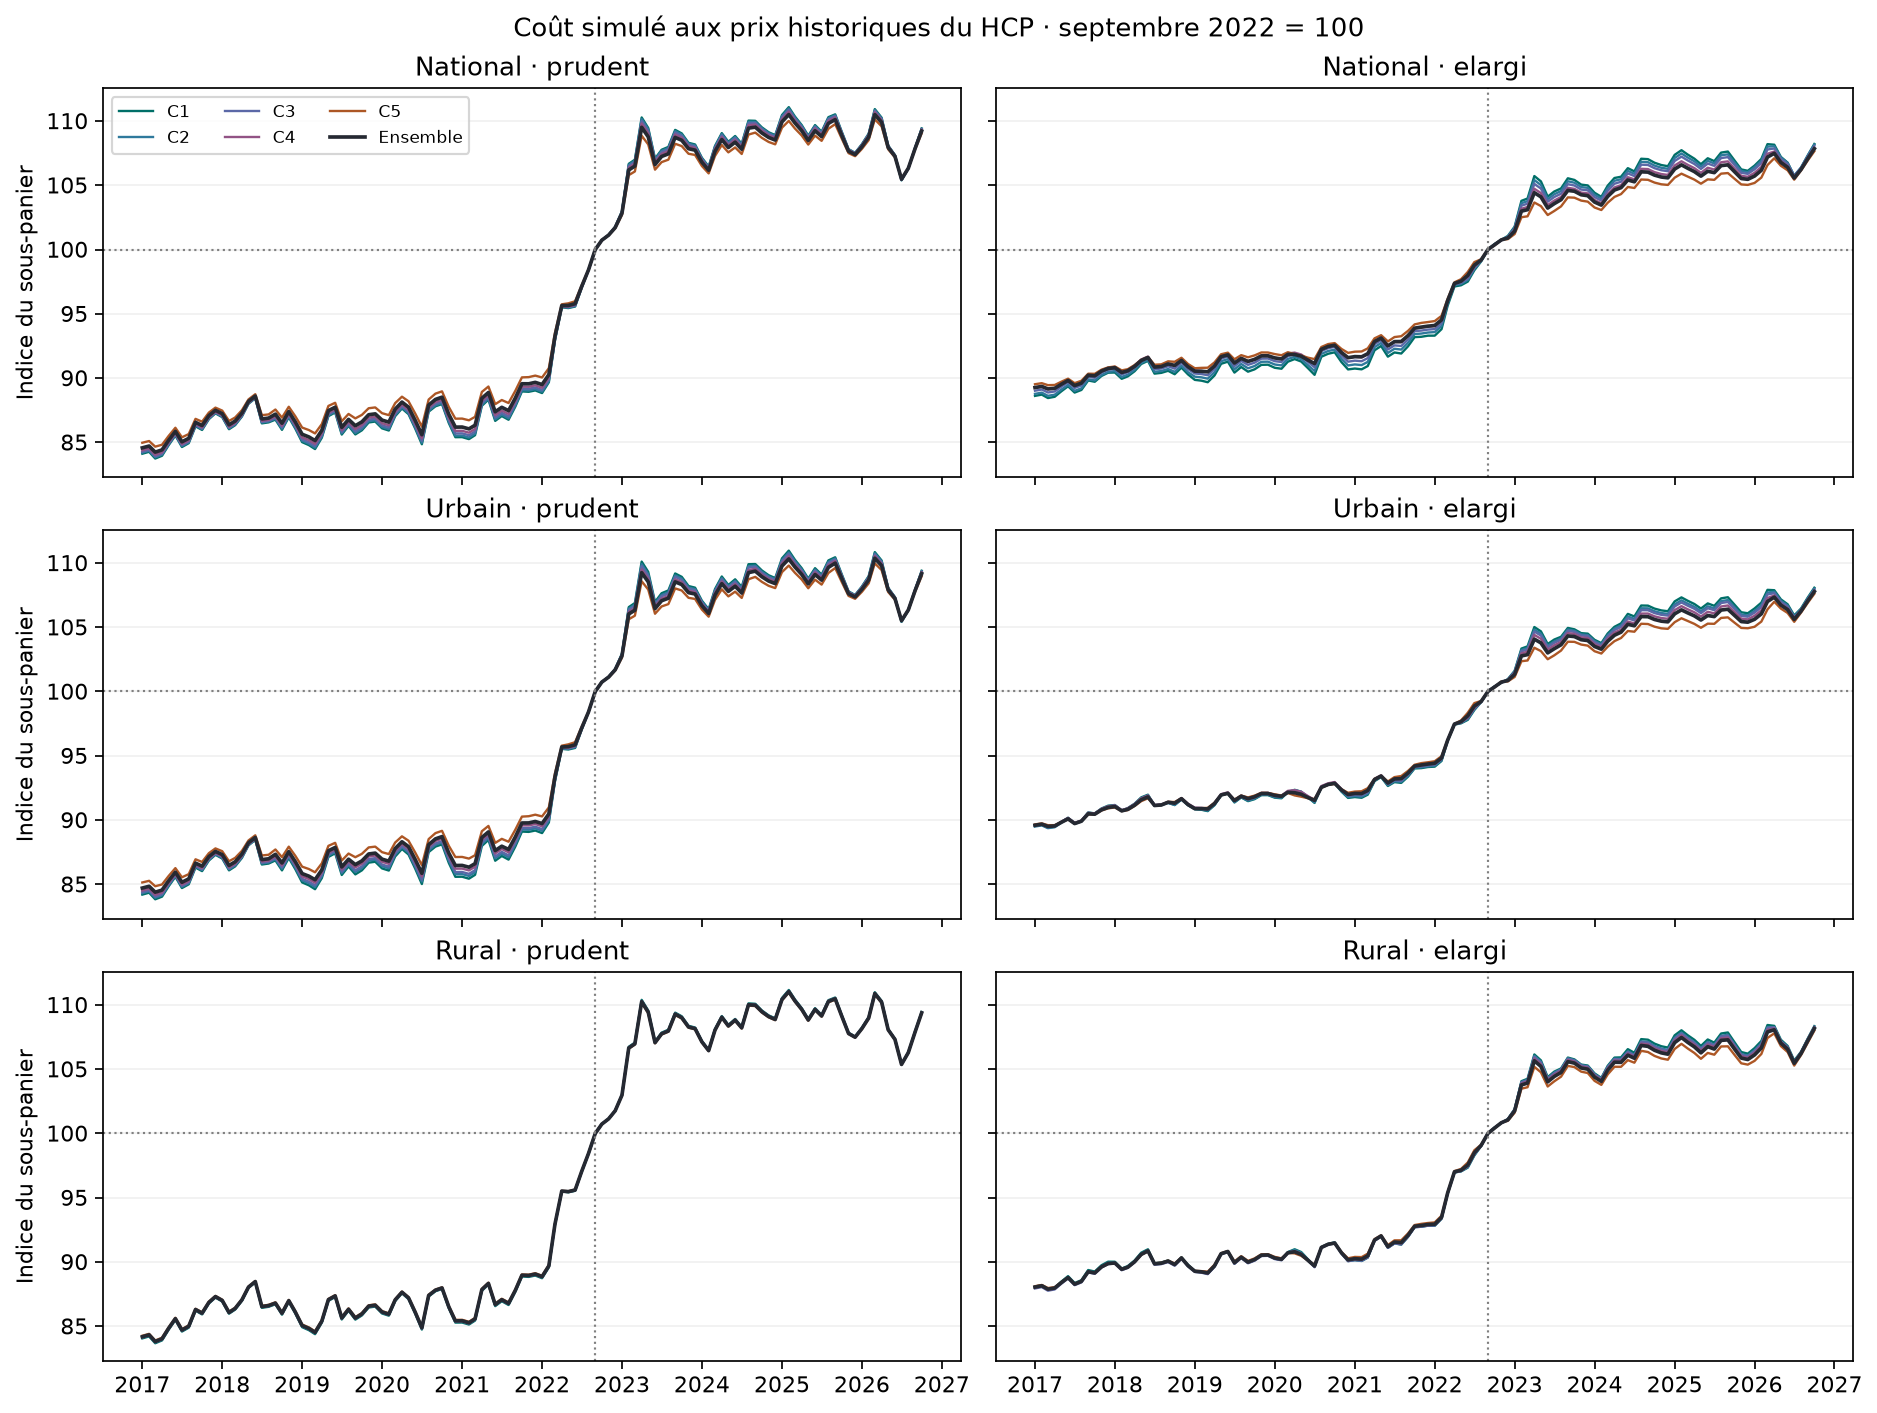

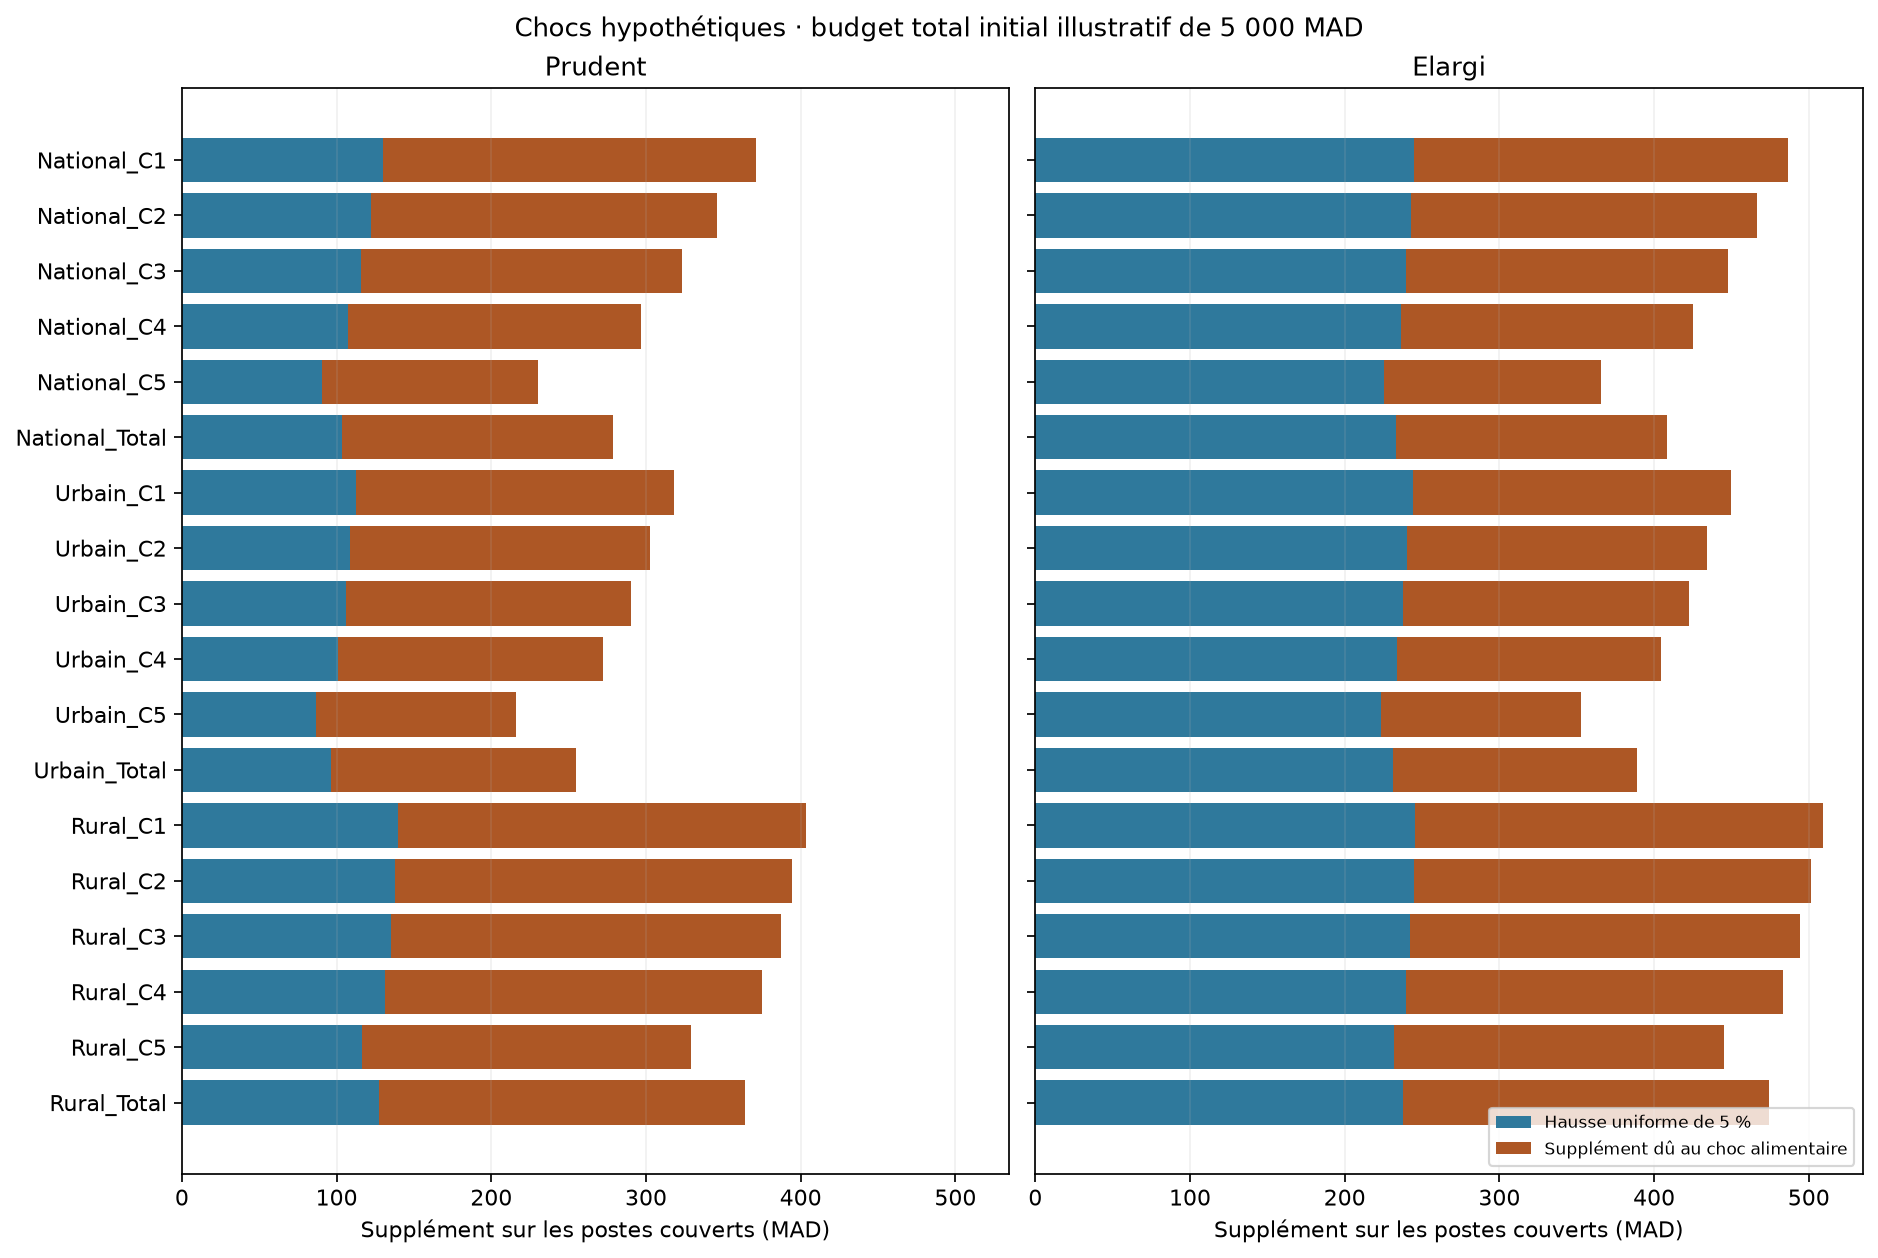

In [4]:
for nom, table in [
    ("04_cout_panier_historique.csv", historique),
    ("04_chocs_hypothetiques.csv", hypotheses),
    ("04_ponderations_sous_paniers.csv", poids_table),
]:
    table.to_csv(sorties / nom, index=False, encoding="utf-8-sig", float_format="%.8f")


def enregistrer(figure, nom):
    chemin = sorties / nom
    figure.savefig(chemin, dpi=155, bbox_inches="tight")
    plt.close(figure)
    display(Image(filename=str(chemin)))


couleurs = ["#006f68", "#2f799c", "#5b68a7", "#925385", "#ad5725", "#252932"]
figure, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True, sharey=True, layout="constrained")
for i, milieu in enumerate(milieux):
    for j, perimetre in enumerate(perimetres):
        axe = axes[i, j]
        for classe, couleur in zip(classes, couleurs):
            profil = f"{milieu}_{classe}"
            serie = historique.loc[
                historique["profil"].eq(profil) & historique["perimetre"].eq(perimetre)
            ]
            axe.plot(serie["date"], serie["indice_cout_sous_panier_base_100_sept_2022"],
                     color=couleur, linewidth=1.7 if classe == "Total" else 1.1,
                     label="Ensemble" if classe == "Total" else classe)
        axe.axvline(reference, color="gray", linestyle=":", linewidth=1)
        axe.axhline(100, color="gray", linestyle=":", linewidth=1)
        axe.set_title(f"{milieu} · {perimetre}")
        axe.grid(axis="y", alpha=0.18)
        if j == 0:
            axe.set_ylabel("Indice du sous-panier")
axes[0, 0].legend(ncol=3, fontsize=8)
figure.suptitle("Coût simulé aux prix historiques du HCP · septembre 2022 = 100")
enregistrer(figure, "04_cout_panier_historique.png")

figure, axes = plt.subplots(1, 2, figsize=(12, 8), sharex=True, sharey=True, layout="constrained")
for axe, perimetre in zip(axes, perimetres):
    base = uniforme.loc[perimetre, "supplement_postes_couverts_mad"]
    total = combine.loc[perimetre, "supplement_postes_couverts_mad"]
    axe.barh(profils.index, base, color="#2f799c", label="Hausse uniforme de 5 %")
    axe.barh(profils.index, total - base, left=base, color="#ad5725",
             label="Supplément dû au choc alimentaire")
    axe.set(title=perimetre.capitalize(), xlabel="Supplément sur les postes couverts (MAD)")
    axe.grid(axis="x", alpha=0.18)
axes[0].invert_yaxis()
axes[1].legend(loc="lower right", fontsize=8)
figure.suptitle("Chocs hypothétiques · budget total initial illustratif de 5 000 MAD")
enregistrer(figure, "04_chocs_hypothetiques.png")

## 4. Interprétation économique

L’interprétation se limite à la dépense nécessaire pour maintenir les quantités du sous-panier. Les profils ont des poids alimentaires et des couvertures différents. Un choc uniforme produit le même taux pour tous les sous-paniers, mais sa contribution au budget total dépend de la couverture. Le supplément dû au choc alimentaire dépend du coefficient d’origine du groupe 01. Le même poste alimentaire figure dans les deux périmètres, donc ce supplément marginal en MAD est identique entre périmètres pour un même profil.

Les comparaisons urbain–rural utilisent la même série de prix pour chaque division. Elles illustrent les différences de structure budgétaire sous des prix communs. La disponibilité des biens, l’autoconsommation et les prix locaux peuvent modifier l’exposition effective. Les groupes non couverts, la substitution entre produits et les revenus ne sont pas estimés.

In [5]:
def nombre_fr(valeur):
    return f"{valeur:.2f}".replace(".", ",")


derniers = historique.loc[
    historique["date"].eq(ipc.index[-1]) & historique["profil"].eq("National_Total")
].set_index("perimetre")
taux_prudent = nombre_fr(derniers.loc["prudent", "variation_depuis_sept_2022_pct"])
taux_elargi = nombre_fr(derniers.loc["elargi", "variation_depuis_sept_2022_pct"])
ligne_u = uniforme.loc[("prudent", "National_Total")]
ligne_c = combine.loc[("prudent", "National_Total")]
couverture_prudente = nombre_fr(derniers.loc["prudent", "couverture_budget_pct"])
couverture_elargie = nombre_fr(derniers.loc["elargi", "couverture_budget_pct"])
montant_u = nombre_fr(ligne_u["supplement_postes_couverts_mad"])
montant_c = nombre_fr(ligne_c["supplement_postes_couverts_mad"])
display(Markdown(
    f"**Ensemble national.** Entre septembre 2022 et octobre 2026, le coût du sous-panier "
    f"évolue de **{taux_prudent} %** dans le périmètre prudent et **{taux_elargi} %** "
    "dans le périmètre élargi. Les périmètres couvrent respectivement "
    f"{couverture_prudente} % et {couverture_elargie} % du budget. "
    "Dans l’illustration à 5 000 MAD, le scénario uniforme ajoute "
    f"**{montant_u} MAD** sur les postes du périmètre prudent. Le scénario combiné "
    f"porte ce supplément à **{montant_c} MAD**."
))

**Ensemble national.** Entre septembre 2022 et octobre 2026, le coût du sous-panier évolue de **9,22 %** dans le périmètre prudent et **7,85 %** dans le périmètre élargi. Les périmètres couvrent respectivement 41,40 % et 93,20 % du budget. Dans l’illustration à 5 000 MAD, le scénario uniforme ajoute **103,50 MAD** sur les postes du périmètre prudent. Le scénario combiné porte ce supplément à **278,85 MAD**.